In [215]:
import numpy as np
import pandas as pd
import itertools
import matplotlib
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from datetime import date
import re
# from tqdm import tqdm
import time
# from pybedtools import BedTool
import random
import math
import pickle
import seaborn as sns
from scipy.stats import percentileofscore, pearsonr, rankdata
# from scipy.spatial.distance import jaccard, euclidean, cosine
# import functools
# import operator
import gzip
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import sys
import os
from functools import partial
from contextlib import closing
from multiprocessing import Pool
import re
import h5py
import tabix
import upsetplot
from wordcloud import WordCloud

today = date.today()

In [2]:
def kde_wrapper(data, bw=0.1):
    fig = plt.figure()
    fig.patch.set_facecolor('white')
    
    sns.kdeplot(data, bw_adjust=bw)
    print(describe(data))
    return fig

**Breaking down scores for each ROI**

In [21]:
# DHS_ooe = np.load('/home/ctrader/region_similarity/data/regions_25kb_CT20220623.DHSoee.npy')
# TF_ooe = np.load('/home/ctrader/region_similarity/data/regions_25kb_CT20220623.TFoee.npy')
# epilogos_ooe = np.load('/home/ctrader/region_similarity/data/regions_25kb_CT20220623.epilogosoee.npy')

In [189]:
f = open('/home/ctrader/region_similarity/data/regions_25kb_CT20220628.cleanedgenesmapped.bed', 'r')
mapped_genes = f.readlines()
f.close()

In [22]:
DHS_ooe_hdf5 = h5py.File('/home/ctrader/region_similarity/data/regions_25kb_CT20220623.DHSoee.hdf5', 'r')
DHS_ooe = DHS_ooe_hdf5['ooe_arr'][:]
DHS_ooe_hdf5.close()
TF_ooe_hdf5 = h5py.File('/home/ctrader/region_similarity/data/regions_25kb_CT20220623.TFoee.hdf5', 'r')
TF_ooe = TF_ooe_hdf5['ooe_arr'][:]
TF_ooe_hdf5.close()
epilogos_ooe_hdf5 = h5py.File('/home/ctrader/region_similarity/data/regions_25kb_CT20220623.epilogosoee.hdf5', 'r')
epilogos_ooe = epilogos_ooe_hdf5['ooe_arr'][:]
epilogos_ooe_hdf5.close()

In [5]:
#loading order of each component
f = open('/home/ctrader/region_similarity/data/regions_25kb_CT20220623.TFmapped.bed', 'r')
TF_component_order = np.array(f.readline().strip().split('\t'))[3:]
f.close()

f = open('/home/ctrader/region_similarity/data/regions_25kb_CT20220623.DHSmapped.bed', 'r')
DHS_component_order = np.array(f.readline().strip().split('\t'))[3:]
f.close()

f = open('/home/ctrader/region_similarity/data/regions_25kb_CT20220623.epilogosmapped.bed', 'r')
epilogos_component_order = np.array(f.readline().strip().split('\t'))[3:]
f.close()

In [6]:
#descriptors for each factor
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/tf_motif_descriptor_dict_CT20220627.pickle', 'rb')
TFfact2descr = pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/DHS_descriptor_dict_CT20220627.pickle', 'rb')
DHSfact2descr = pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/epilogos_descriptor_dict_CT20220627.pickle', 'rb')
epilogosfact2descr = pickle.load(pickle_in)

In [25]:
DHS_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220623.DHScosine.hdf5'
TF_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220623.TFcosine.hdf5'
epilogos_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220623.epilogoscosine.hdf5'
regions_path = '/home/ctrader/region_similarity/data/Altius_25kb_hg38_maxMean_CT20220613.sorted.c1t3.bed'
gz_file_path = '/home/ctrader/region_similarity/data/Altius_25kb_hg38_maxMean_CT20220613.sorted.c1t3.rownum4.bed.gz'

In [8]:
DHS_hdf5 = h5py.File(DHS_hdf5_path, 'r')
DHS_scaled_vals_full = DHS_hdf5['top_1000_scaled_vals'][:]
DHS_cosine_vals_full = DHS_hdf5['top_1000_cosine_vals'][:]
DHS_similar_regions_full = DHS_hdf5['top_1000_similar_regions'][:]
DHS_hdf5.close()

TF_hdf5 = h5py.File(TF_hdf5_path, 'r')
TF_scaled_vals_full = TF_hdf5['top_1000_scaled_vals'][:]
TF_cosine_vals_full = TF_hdf5['top_1000_cosine_vals'][:]
TF_similar_regions_full = TF_hdf5['top_1000_similar_regions'][:]
TF_hdf5.close()

epilogos_hdf5 = h5py.File(epilogos_hdf5_path, 'r')
epilogos_scaled_vals_full = epilogos_hdf5['top_1000_scaled_vals'][:]
epilogos_cosine_vals_full = epilogos_hdf5['top_1000_cosine_vals'][:]
epilogos_similar_regions_full = epilogos_hdf5['top_1000_similar_regions'][:]
epilogos_hdf5.close()

In [9]:
def combine_scores(DHS_count_scaled_vals, DHS_count_similar_regions, TF_count_scaled_vals, TF_count_similar_regions, epilogos_score_scaled_vals, epilogos_score_similar_regions):
    #max ind for combined score array
    max_ind = np.max([DHS_count_similar_regions, TF_count_similar_regions, epilogos_score_similar_regions])
    #DHS scores
    DHS_arr = np.zeros(max_ind + 1)
    DHS_arr[DHS_count_similar_regions] = DHS_count_scaled_vals
    #epilogos scores
    epilogos_arr = np.zeros(max_ind + 1)
    epilogos_arr[epilogos_score_similar_regions] = epilogos_score_scaled_vals
    #TF motif scores
    TF_arr = np.zeros(max_ind + 1)
    TF_arr[TF_count_similar_regions] = TF_count_scaled_vals

    #scoring all metrics
    score_arr = 1 - ((1 - epilogos_arr) * (1 - DHS_arr) * (1 - TF_arr))
    
    ##labeling most contributing metrics for each region
    contributing_cosine_arr = np.argmax(np.vstack((DHS_arr, TF_arr, epilogos_arr)), axis=0)#

    return score_arr, contributing_cosine_arr

def region_return(score_arr, contributing_cosine_arr, roi, regions_path):
    #top 100 region inds and scores
    rec_inds = np.argsort(-score_arr)[:100]
    top_region_inds = np.append(roi, rec_inds)
    top_region_scores = np.append(1, score_arr[rec_inds])
    
    #most contributing metrics to the top 100 scoring regions
    top_region_contributions = np.append('ROI', contributing_cosine_arr[rec_inds])
    top_region_contributions = np.where(top_region_contributions=='0', 'DHS', top_region_contributions)
    top_region_contributions = np.where(top_region_contributions=='1', 'TF', top_region_contributions)
    top_region_contributions = np.where(top_region_contributions=='2', 'epilogos', top_region_contributions)
    
    #combining scores and contributions
    score_contribution_comb = np.char.add(np.char.add(np.round(top_region_scores, 4).astype(str), 
                                                      np.array([' - ']*len(top_region_scores))), 
                                          top_region_contributions)
    
    #new 6/17/22 - adding top comp to roiurls
    DHS_roi_rank = rankdata(-DHS_ooe[top_region_inds[0]])
    TF_roi_rank = rankdata(-TF_ooe[top_region_inds[0]])
    epilogos_roi_mean_rank = rankdata(-epilogos_ooe[top_region_inds[0]][:18])
    epilogos_roi_max_rank = rankdata(-epilogos_ooe[top_region_inds[0]][18:])
    metric_top_comps = ['']
    for ind in range(1, len(top_region_contributions)):
        metric = top_region_contributions[ind]
        if metric=='DHS':
            DHS_ind_rank = rankdata(-DHS_ooe[top_region_inds[ind]])
            top_comp = np.argsort((DHS_roi_rank+DHS_ind_rank)/2)[0]
            metric_top_comps.append(' (' + DHS_component_order[top_comp] + ')')
        if metric=='TF':
            TF_ind_rank = rankdata(-TF_ooe[top_region_inds[ind]])
            top_comp = np.argsort((TF_roi_rank+TF_ind_rank)/2)[0]
            metric_top_comps.append(' (' + TF_component_order[top_comp] + ')')
        if metric=='epilogos':
            epilogos_ind_mean_rank = rankdata(-epilogos_ooe[top_region_inds[ind]][:18])
            epilogos_ind_max_rank = rankdata(-epilogos_ooe[top_region_inds[ind]][18:])
            top_mean_comp = np.argsort((epilogos_roi_mean_rank + epilogos_ind_mean_rank)/2)[0]
            top_max_comp = np.argsort((epilogos_roi_max_rank + epilogos_ind_max_rank)/2)[0]
            metric_top_comps.append(' (' + epilogos_component_order[top_mean_comp] + '/' + 
                                    epilogos_component_order[top_max_comp] + ')')
    metric_top_comps = np.array(metric_top_comps)
    score_contribution_comb = np.char.add(score_contribution_comb, metric_top_comps)
    
    #find genomic locations
    f = open(regions_path, 'r')
    regions = f.readlines()
    top_regions = []
    for ind in top_region_inds:
        top_regions.append(regions[ind].strip().split())
    f.close()
    top_regions = np.array(top_regions)
    top_regions = np.hstack((top_regions, score_contribution_comb.reshape((len(score_contribution_comb), 1))))#

    link_path, bed_path_name = roi_url(roi, top_regions)
    print(link_path, flush=True)

    return bed_path_name, top_region_inds

def roi_url(roi, top_regions):
    today = date.today()
    roi_url_name = 'region_comparison_recommended_regions_roi_'+str(roi)+'_scale_25kb_notebook_CT' + today.strftime("%Y%m%d") + '.bed'
    bed_path_name = os.path.join('/home/ctrader/public_html/', roi_url_name)
    np.savetxt(bed_path_name, top_regions, delimiter='\t', fmt='%s')
    link_path = 'https://epilogos.altius.org:3001/?application=viewer&sampleSet=vC&mode=single&genome=hg38&model=18&complexity=KL&group=all&chrLeft=chr1&chrRight=chr1&start=8000&stop=35000&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + roi_url_name
    return link_path, bed_path_name

In [10]:
def breakdown_score(ind):
    DHS_ooe_1v2 = DHS_ooe[top_region_inds[[0, ind]]]
    TF_ooe_1v2 = TF_ooe[top_region_inds[[0, ind]]]
    epilogos_ooe_1v2 = epilogos_ooe[top_region_inds[[0, ind]]]

    #cosine similarity
    print('ROI =', roi)
    print('#%s in ROIurl' %(ind+1))
    print()
    print('DHS Cosine Similarity =', np.round(cosine_similarity(DHS_ooe_1v2[0].reshape(1, -1), DHS_ooe_1v2[1].reshape(1, -1))[0, 0], 4))
    print('TF Cosine Similarity =', np.round(cosine_similarity(TF_ooe_1v2[0].reshape(1, -1), TF_ooe_1v2[1].reshape(1, -1))[0, 0], 4))
    print('Epilogos Cosine Similarity =', np.round(cosine_similarity(epilogos_ooe_1v2[0].reshape(1, -1), epilogos_ooe_1v2[1].reshape(1, -1))[0, 0], 4))
    print()
    print('1000th DHS Cosine Similarity for ROI =', np.round(DHS_cosine_vals_full[roi, -1], 4))
    print('1000th TF Cosine Similarity for ROI =', np.round(TF_cosine_vals_full[roi, -1], 4))
    print('1000th Epilogos Cosine Similarity for ROI =', np.round(epilogos_cosine_vals_full[roi, -1], 4))
    print()
    print('DHS Scaled Score =', np.round(DHS_arr[top_region_inds[ind]], 4))
    print('TF Scaled Score =', np.round(TF_arr[top_region_inds[ind]], 4))
    print('Epilogos Scaled Score =', np.round(epilogos_arr[top_region_inds[ind]], 4))
    print()
    print('Total Score =', 
          np.round(1 - ((1-DHS_arr[top_region_inds[ind]])*(1-TF_arr[top_region_inds[ind]])*(1-epilogos_arr[top_region_inds[ind]])), 4))
    print()

    #scatter plot
    fig = plt.figure(figsize=(8,8))
    fig.patch.set_facecolor('white')

    size=30

    plt.scatter(DHS_ooe_1v2[0], DHS_ooe_1v2[1], c='#1f77b4', s=size)
    plt.scatter(TF_ooe_1v2[0], TF_ooe_1v2[1], c='#ff7f0e', s=size)
    plt.scatter(epilogos_ooe_1v2[0, :18], epilogos_ooe_1v2[1, :18], c='#2ca02c', s=size)
    plt.scatter(epilogos_ooe_1v2[0, 18:], epilogos_ooe_1v2[1, 18:], marker='x', c='#2ca02c', s=size)


    plt.xlim([np.min([np.min(DHS_ooe_1v2), np.min(TF_ooe_1v2), np.min(epilogos_ooe_1v2)])-0.5, 
              np.max([np.max(DHS_ooe_1v2), np.max(TF_ooe_1v2), np.max(epilogos_ooe_1v2)])+0.5])
    plt.ylim([np.min([np.min(DHS_ooe_1v2), np.min(TF_ooe_1v2), np.min(epilogos_ooe_1v2)])-0.5, 
              np.max([np.max(DHS_ooe_1v2), np.max(TF_ooe_1v2), np.max(epilogos_ooe_1v2)])+0.5])

    plt.legend(['DHS Counts', 'TF Motif Counts', 'Epilogos Mean', 'Epilogos Max'])

    plt.xlabel('ROI OOE Values')
    plt.ylabel('Similar Region OOE Values')
    title='Comparing OOE Values Between ROI (%s) and Rank %s Similar Region (%s)' %(roi, ind, top_region_inds[ind])
    plt.title(title)
    print(title)
    plt.show()

In [273]:
#find roi
genomic_location = 'chr20:19756800-19756801'
gz_tb = tabix.open(gz_file_path)
roi = int(list(gz_tb.querys(genomic_location))[0][3])

# #determine roi
roi=12345

#determine roi - best
roi=21861 #np.argsort(-average_of_scores)[6]
# roi=np.argsort(-average_of_scores)[0]

In [274]:
print('roi = ' + str(roi), flush=True)
t = time.time()
###Load rank and ind arrays
#DHS counts
DHS_hdf5 = h5py.File(DHS_hdf5_path, 'r')
DHS_count_scaled_vals = DHS_hdf5['top_1000_scaled_vals'][roi]
DHS_count_similar_regions = DHS_hdf5['top_1000_similar_regions'][roi]
DHS_hdf5.close()

#TF motif counts
TF_hdf5 = h5py.File(TF_hdf5_path, 'r')
TF_count_scaled_vals = TF_hdf5['top_1000_scaled_vals'][roi]
TF_count_similar_regions = TF_hdf5['top_1000_similar_regions'][roi]
TF_hdf5.close()

#epilogos score sum and max
epilogos_hdf5 = h5py.File(epilogos_hdf5_path, 'r')
epilogos_score_scaled_vals = epilogos_hdf5['top_1000_scaled_vals'][roi]
epilogos_score_similar_regions = epilogos_hdf5['top_1000_similar_regions'][roi]
epilogos_hdf5.close()

###Combine scores 
#
score_arr, contributing_cosine_arr = combine_scores(DHS_count_scaled_vals, DHS_count_similar_regions, TF_count_scaled_vals, TF_count_similar_regions, epilogos_score_scaled_vals, epilogos_score_similar_regions)


###Return regions
bed_path_name, top_region_inds = region_return(score_arr, contributing_cosine_arr, roi, regions_path)
print(time.time()-t)

roi = 21861
https://epilogos.altius.org:3001/?application=viewer&sampleSet=vC&mode=single&genome=hg38&model=18&complexity=KL&group=all&chrLeft=chr1&chrRight=chr1&start=8000&stop=35000&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fregion_comparison_recommended_regions_roi_21861_scale_25kb_notebook_CT20220628.bed
0.22546076774597168


In [275]:
max_ind = np.max([DHS_count_similar_regions, TF_count_similar_regions, epilogos_score_similar_regions])
#DHS scores
DHS_arr = np.zeros(max_ind + 1)
DHS_arr[DHS_count_similar_regions] = DHS_count_scaled_vals
#epilogos scores
epilogos_arr = np.zeros(max_ind + 1)
epilogos_arr[epilogos_score_similar_regions] = epilogos_score_scaled_vals
#TF motif scores
TF_arr = np.zeros(max_ind + 1)
TF_arr[TF_count_similar_regions] = TF_count_scaled_vals

Text(0.5, 1.0, 'Scoring Breakdown for ROI 21861')

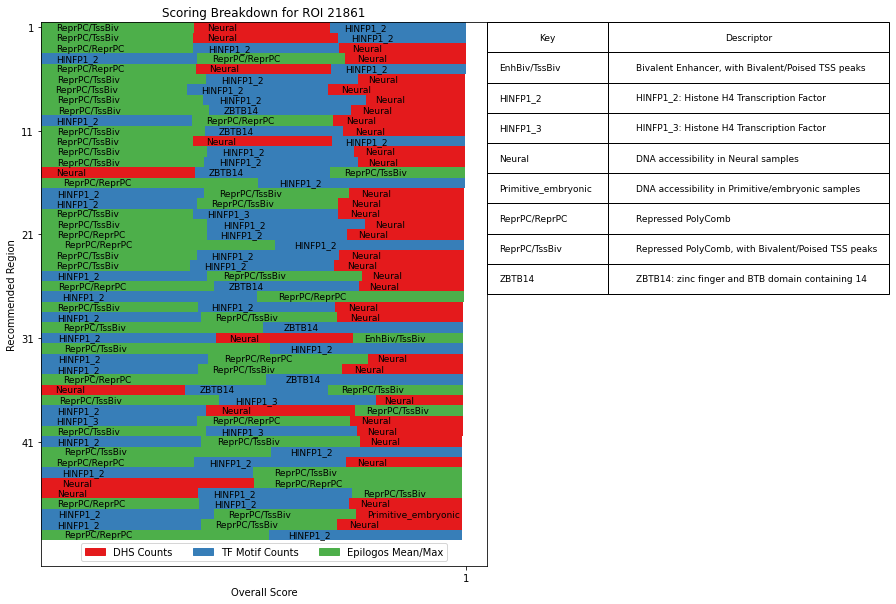

In [276]:
#sideways bar plots ordered by biggest component
DHS_arr_top_100 = DHS_arr[top_region_inds[1:]]
TF_arr_top_100 = TF_arr[top_region_inds[1:]]
epilogos_arr_top_100 = epilogos_arr[top_region_inds[1:]]

metric_sum_top_100 = DHS_arr_top_100 + TF_arr_top_100 + epilogos_arr_top_100

score_arr_top_100 = score_arr[top_region_inds[1:]]

DHS_arr_bar_scaled = DHS_arr_top_100 / metric_sum_top_100 * score_arr_top_100
TF_arr_bar_scaled = TF_arr_top_100 / metric_sum_top_100 * score_arr_top_100
epilogos_arr_bar_scaled = epilogos_arr_top_100 / metric_sum_top_100 * score_arr_top_100

metrics_bar_scaled = np.array([DHS_arr_bar_scaled[:50], TF_arr_bar_scaled[:50], epilogos_arr_bar_scaled[:50]])
metrics_bar_scaled_inds = np.argsort(-metrics_bar_scaled, axis=0)
metrics_bar_scaled_vals = -np.sort(-metrics_bar_scaled, axis=0)

colors = np.array(['#e41a1c', '#377eb8', '#4daf4a'])


#plotting
fig = plt.figure(figsize=(8, 10))
fig.patch.set_facecolor('white')

plt.barh(np.flip(np.arange(50)), metrics_bar_scaled_vals[0], color=colors[metrics_bar_scaled_inds[0]], height=1, align='center')
plt.barh(np.flip(np.arange(50)), metrics_bar_scaled_vals[1], left=metrics_bar_scaled_vals[0], color=colors[metrics_bar_scaled_inds[1]], height=1, align='center')
plt.barh(np.flip(np.arange(50)), metrics_bar_scaled_vals[2], left=metrics_bar_scaled_vals[0]+metrics_bar_scaled_vals[1], color=colors[metrics_bar_scaled_inds[2]], height=1, align='center')

#label top comps
DHS_roi_rank = rankdata(-DHS_ooe[top_region_inds[0]])
TF_roi_rank = rankdata(-TF_ooe[top_region_inds[0]])
epilogos_roi_mean_rank = rankdata(-epilogos_ooe[top_region_inds[0]][:18])
epilogos_roi_max_rank = rankdata(-epilogos_ooe[top_region_inds[0]][18:])
top_factors = []
for i in range(len(metrics_bar_scaled_vals[0])):
    start_val = 0
    for metric, val in zip(metrics_bar_scaled_inds[:, i], metrics_bar_scaled_vals[:, i]):
        if ((metric==0) & (val>0)):
            DHS_i_rank = rankdata(-DHS_ooe[top_region_inds[i+1]])
            top_comp = np.argsort((DHS_roi_rank+DHS_i_rank)/2)[0]
            plt.text(start_val + val/10, 
                     len(metrics_bar_scaled_vals[0])-1.25-i, 
                     DHS_component_order[top_comp], 
                     fontsize=9)
            top_factors.append(DHS_component_order[top_comp])
        elif ((metric==1) & (val>0)):
            TF_i_rank = rankdata(-TF_ooe[top_region_inds[i+1]])
            top_comp = np.argsort((TF_roi_rank+TF_i_rank)/2)[0]
            plt.text(start_val + val/10, 
                     len(metrics_bar_scaled_vals[0])-1.25-i, 
                     TF_component_order[top_comp], 
                     fontsize=9)
            top_factors.append(TF_component_order[top_comp])
        elif ((metric==2) & (val>0)):
            epilogos_i_mean_rank = rankdata(-epilogos_ooe[top_region_inds[i+1]][:18])
            epilogos_i_max_rank = rankdata(-epilogos_ooe[top_region_inds[i+1]][18:])
            top_mean_comp = np.argsort((epilogos_roi_mean_rank + epilogos_i_mean_rank)/2)[0]
            top_max_comp = np.argsort((epilogos_roi_max_rank + epilogos_i_max_rank)/2)[0]
            plt.text(start_val + val/10, 
                     len(metrics_bar_scaled_vals[0])-1.25-i, 
                     epilogos_component_order[top_mean_comp] + '/' + epilogos_component_order[top_max_comp], 
                     fontsize=9)
            top_factors.append(epilogos_component_order[top_mean_comp] + '/' + epilogos_component_order[top_max_comp])
        start_val+=val

#look up table
top_factors = np.unique(top_factors)
factor_bar_arr = []
for factor in top_factors:
    factor_l = factor.split('/')
    if len(factor_l) == 2: #epilogos
        if factor_l[0]==factor_l[1]:
            factor_bar_arr.append(epilogosfact2descr[factor_l[0]])
        else:
            factor_bar_arr.append(epilogosfact2descr[factor_l[0]] + ', with ' + epilogosfact2descr[factor_l[1]] + ' peaks')
    elif factor in DHSfact2descr: #DHS
        factor_bar_arr.append(DHSfact2descr[factor])
    else: #TF motifs
        factor_bar_arr.append(factor + ': ' + TFfact2descr[factor])
factor_bar_arr = np.array(factor_bar_arr)
lookup_table = np.hstack((top_factors.reshape((-1, 1)), factor_bar_arr.reshape((-1, 1))))
t = plt.table(lookup_table, 
              cellLoc='left',
              colLabels=['Key', 'Descriptor'],
              bbox=[1, 0.5, 0.9, 0.5], 
              colWidths=[0.15, 0.35])
t.auto_set_font_size(False)
t.set_fontsize(9)

plt.yticks(np.arange(9, 51, 10), np.flip(np.arange(1, 42, 10)))
plt.ylim([-3, 49.5])
plt.xticks([1])
DHS_patch = mpatches.Patch(color='#e41a1c', label='DHS Counts')
TF_patch = mpatches.Patch(color='#377eb8', label='TF Motif Counts')
epilogos_patch = mpatches.Patch(color='#4daf4a', label='Epilogos Mean/Max')
plt.legend(handles=[DHS_patch, TF_patch, epilogos_patch], loc='lower center', ncol=3)
plt.xlabel('Overall Score')
plt.ylabel('Recommended Region')
title = 'Scoring Breakdown for ROI %s' %(roi)
plt.title(title)

Breakdown of Factors with Top 100 Regions for ROI 21861 (chr13:112051600-112076600)


<Figure size 1440x720 with 0 Axes>

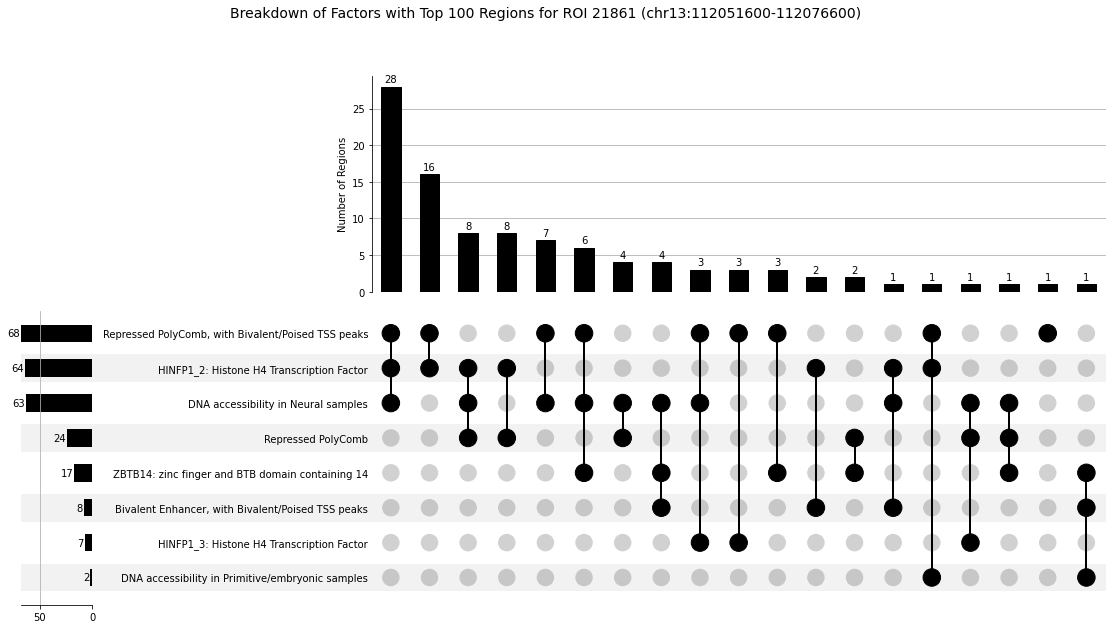

In [277]:
DHS_arr_top_100 = DHS_arr[top_region_inds[1:]]
TF_arr_top_100 = TF_arr[top_region_inds[1:]]
epilogos_arr_top_100 = epilogos_arr[top_region_inds[1:]]

#roi comps
DHS_roi_rank = rankdata(-DHS_ooe[top_region_inds[0]])
TF_roi_rank = rankdata(-TF_ooe[top_region_inds[0]])
epilogos_roi_mean_rank = rankdata(-epilogos_ooe[top_region_inds[0]][:18])
epilogos_roi_max_rank = rankdata(-epilogos_ooe[top_region_inds[0]][18:])

#find top comps for each metric/recommended region
DHS_top_comps_100 = []
for i in range(len(DHS_arr_top_100)):
    if DHS_arr_top_100[i] > 0:
        DHS_i_rank = rankdata(-DHS_ooe[top_region_inds[i+1]])
        top_comp = np.argsort((DHS_roi_rank+DHS_i_rank)/2)[0]
        DHS_top_comps_100.append(DHS_component_order[top_comp])
    else:
        DHS_top_comps_100.append(np.nan)
DHS_top_comps_100 = np.array(DHS_top_comps_100)

TF_top_comps_100 = []
for i in range(len(TF_arr_top_100)):
    if TF_arr_top_100[i] > 0:
        TF_i_rank = rankdata(-TF_ooe[top_region_inds[i+1]])
        top_comp = np.argsort((TF_roi_rank+TF_i_rank)/2)[0]
        TF_top_comps_100.append(TF_component_order[top_comp])
    else:
        TF_top_comps_100.append(np.nan)
TF_top_comps_100 = np.array(TF_top_comps_100)

epilogos_mean_top_comps_100 = []
epilogos_max_top_comps_100 = []
epilogos_top_comps_100 = []
for i in range(len(epilogos_arr_top_100)):
    if epilogos_arr_top_100[i] > 0:
        epilogos_i_mean_rank = rankdata(-epilogos_ooe[top_region_inds[i+1]][:18])
        epilogos_i_max_rank = rankdata(-epilogos_ooe[top_region_inds[i+1]][18:])
        top_mean_comp = np.argsort((epilogos_roi_mean_rank + epilogos_i_mean_rank)/2)[0]
        top_max_comp = np.argsort((epilogos_roi_max_rank + epilogos_i_max_rank)/2)[0]
        epilogos_mean_top_comps_100.append(epilogos_component_order[top_mean_comp])
        epilogos_max_top_comps_100.append(epilogos_component_order[top_max_comp])
        epilogos_top_comps_100.append(epilogos_component_order[top_mean_comp] + '/' + epilogos_component_order[top_max_comp])
    else:
        epilogos_mean_top_comps_100.append(np.nan)
        epilogos_max_top_comps_100.append(np.nan)
        epilogos_top_comps_100.append(np.nan)
epilogos_mean_top_comps_100 = np.array(epilogos_mean_top_comps_100)
epilogos_max_top_comps_100 = np.array(epilogos_max_top_comps_100)
epilogos_top_comps_100 = np.array(epilogos_top_comps_100)

DHS_top_comps_100_unique = np.unique(DHS_top_comps_100[DHS_top_comps_100!='nan'])
TF_top_comps_100_unique = np.unique(TF_top_comps_100[TF_top_comps_100!='nan'])
# epilogos_mean_top_comps_100_unique = np.unique(epilogos_mean_top_comps_100[epilogos_mean_top_comps_100!='nan'])
# epilogos_max_top_comps_100_unique = np.unique(epilogos_max_top_comps_100[epilogos_max_top_comps_100!='nan'])
epilogos_top_comps_100_unique = np.unique(epilogos_top_comps_100[epilogos_top_comps_100!='nan'])

labels = []
count_data = []
for DHS_factor in DHS_top_comps_100_unique:
    for TF_factor in TF_top_comps_100_unique:
        for epilogos_factor in epilogos_top_comps_100_unique:
            #all 3
            labels.append([DHS_factor, TF_factor, epilogos_factor])
            count_data.append(len(np.arange(len(DHS_top_comps_100))[((DHS_top_comps_100==DHS_factor) & 
                                                                    (TF_top_comps_100==TF_factor) &
                                                                    (epilogos_top_comps_100==epilogos_factor))]))
            #2/3
            if [DHS_factor, TF_factor] not in labels:
                labels.append([DHS_factor, TF_factor])
                count_data.append(len(np.arange(len(DHS_top_comps_100))[((DHS_top_comps_100==DHS_factor) & 
                                                                        (TF_top_comps_100==TF_factor) &
                                                                        (epilogos_top_comps_100=='nan'))]))
            if [DHS_factor, epilogos_factor] not in labels:
                labels.append([DHS_factor, epilogos_factor])
                count_data.append(len(np.arange(len(DHS_top_comps_100))[((DHS_top_comps_100==DHS_factor) & 
                                                                        (TF_top_comps_100=='nan') &
                                                                        (epilogos_top_comps_100==epilogos_factor))]))
            if [TF_factor, epilogos_factor] not in labels:
                labels.append([TF_factor, epilogos_factor])
                count_data.append(len(np.arange(len(DHS_top_comps_100))[((DHS_top_comps_100=='nan') & 
                                                                        (TF_top_comps_100==TF_factor) &
                                                                        (epilogos_top_comps_100==epilogos_factor))]))
            #1/3
            if [DHS_factor] not in labels:
                labels.append([DHS_factor])
                count_data.append(len(np.arange(len(DHS_top_comps_100))[((DHS_top_comps_100==DHS_factor) & 
                                                                        (TF_top_comps_100=='nan') &
                                                                        (epilogos_top_comps_100=='nan'))]))
            if [epilogos_factor] not in labels:
                labels.append([epilogos_factor])
                count_data.append(len(np.arange(len(DHS_top_comps_100))[((DHS_top_comps_100=='nan') & 
                                                                        (TF_top_comps_100=='nan') &
                                                                        (epilogos_top_comps_100==epilogos_factor))]))
            if [TF_factor] not in labels:
                labels.append([TF_factor])
                count_data.append(len(np.arange(len(DHS_top_comps_100))[((DHS_top_comps_100=='nan') & 
                                                                        (TF_top_comps_100==TF_factor) &
                                                                        (epilogos_top_comps_100=='nan'))]))
count_data = np.array(count_data)
#get descriptor labels
descriptor_labels = []
for combo in labels:
    combo_labels = []
    for factor in combo:
        factor_l = factor.split('/')
        if len(factor_l) == 2: #epilogos
            if factor_l[0]==factor_l[1]:
                combo_labels.append(epilogosfact2descr[factor_l[0]])
            else:
                combo_labels.append(epilogosfact2descr[factor_l[0]] + ', with ' + epilogosfact2descr[factor_l[1]] + ' peaks')
        elif factor in DHSfact2descr: #DHS
            combo_labels.append(DHSfact2descr[factor])
        else: #TF motifs
            combo_labels.append(factor + ': ' + TFfact2descr[factor])
    descriptor_labels.append(combo_labels)
descriptor_labels = np.array(descriptor_labels, dtype=object)

upset_data = upsetplot.from_memberships(descriptor_labels, data=count_data)

#sorting upset categories
upset_factors = np.array(upset_data.index.names)
upset_factor_counts = np.array([])
for i in range(len(upset_factors)):
    upset_factor_counts = np.append(upset_factor_counts, np.sum(upset_data.unstack(level=i)[True]))
upset_factors_sorted = upset_factors[np.argsort(upset_factor_counts)]
sorted_upset_data = upset_data.reorder_levels(upset_factors_sorted)

fig = plt.figure(figsize=(20,10))

upsetplot.plot(sorted_upset_data, 
               sort_categories_by=None, 
               show_counts=True, 
               min_subset_size=1, 
               sort_by='cardinality', 
               element_size=50)

f = open(regions_path, 'r')
regions = f.readlines()
regions = regions[roi].strip().split('\t')
genome_coords = regions[0] + ':' + regions[1] + '-' + regions[2]
f.close()

plt.ylabel('Number of Regions')
title='Breakdown of Factors with Top 100 Regions for ROI %s (%s)' %(roi, genome_coords)
plt.suptitle(title, fontsize=14)
print(title)

Text(0.5, 1.0, 'Gene Descriptions for ROI 21861 (chr13:112051600-112076600) and Top 100 Regions')

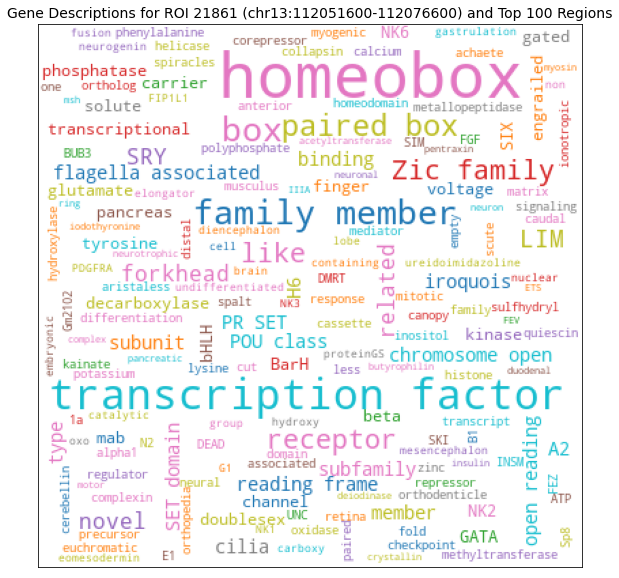

In [283]:
#word cloud
gene_descriptions = ''
for i in top_region_inds:
#     print(mapped_genes[i])
    line = re.split(';|\t|\|', mapped_genes[i].strip())
    descriptions = line[7::5]
    gene_descriptions += ''.join(descriptions) + ' '

fig = plt.figure(figsize=(10, 10))
fig.patch.set_facecolor('white')

stop_words = ['of', 'the', 'a', 'protein', 'and']

gene_wc = WordCloud(width=400, 
                    height=400, 
                    min_word_length=2, 
                    min_font_size=6, 
                    background_color='white', 
                    colormap='tab10', 
                    stopwords=stop_words, 
                    relative_scaling=0.5).generate(gene_descriptions)
plt.imshow(gene_wc)

plt.xticks([])
plt.yticks([])

f = open(regions_path, 'r')
regions = f.readlines()
regions = regions[roi].strip().split('\t')
genome_coords = regions[0] + ':' + regions[1] + '-' + regions[2]
title = 'Gene Descriptions for ROI %s (%s) and Top 100 Regions' %(roi, genome_coords)
plt.title(title, fontsize=14)

In [280]:
gene_descriptions

'SRY-box transcription factor 1 distal-less homeobox 6 retina and anterior neural fold homeobox complexin 4 H6 family homeobox 1 spalt like transcription factor 3 FEZ family zinc finger 2 forkhead box E1 one cut homeobox 1 protein tyrosine phosphatase receptor type N2 LIM homeobox 5 SKI family transcriptional corepressor 2 PR/SET domain 13 NK6 homeobox 1 phenylalanine hydroxylase achaete-scute family bHLH transcription factor 1 POU class 4 homeobox 2 orthopedia homeobox iroquois homeobox 4 POU class 4 homeobox 1 paired box 3 novel protein, ortholog of Gm2102 (M. musculus) engrailed homeobox 2 canopy FGF signaling regulator 1 novel transcript cilia and flagella associated protein 77 BarH like homeobox 1 DEAD-box helicase 31 glutamate ionotropic receptor kainate type subunit 3 GATA binding protein 4 forkhead box B1 BarH like homeobox 2 Zic family member 4 Zic family member 1 forkhead box A2 UNC homeobox cerebellin 1 precursor LIM homeobox 2  H6 family homeobox 3 H6 family homeobox 2 BUB3

All Regions Scoring Breakdown for ROI 21861


<Figure size 720x720 with 0 Axes>

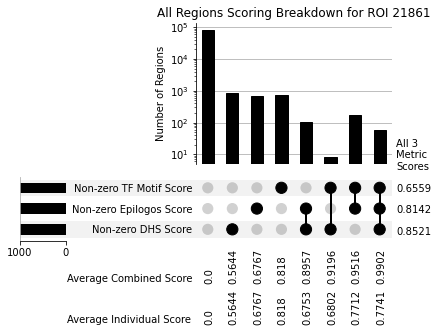

In [125]:
#all regions
mask_all3 = (DHS_arr!=0) & (TF_arr!=0) & (epilogos_arr!=0)
mask_dt = (DHS_arr!=0) & (TF_arr!=0) & (epilogos_arr==0)
mask_de = (DHS_arr!=0) & (TF_arr==0) & (epilogos_arr!=0)
mask_et = (DHS_arr==0) & (TF_arr!=0) & (epilogos_arr!=0)
mask_d = (DHS_arr!=0) & (TF_arr==0) & (epilogos_arr==0)
mask_t = (DHS_arr==0) & (TF_arr!=0) & (epilogos_arr==0)
mask_e = (DHS_arr==0) & (TF_arr==0) & (epilogos_arr!=0)
mask_none = (DHS_arr==0) & (TF_arr==0) & (epilogos_arr==0)

count_data = [len(DHS_arr[mask_all3]), 
              len(DHS_arr[mask_dt]), 
              len(DHS_arr[mask_de]),
              len(DHS_arr[mask_et]),
              len(DHS_arr[mask_d]),
              len(DHS_arr[mask_t]),
              len(DHS_arr[mask_e]),
              len(DHS_arr[mask_none])]

max_count = np.max(count_data)

upset_data = upsetplot.from_memberships(
    [['Non-zero DHS Score', 'Non-zero TF Motif Score', 'Non-zero Epilogos Score'],
     ['Non-zero DHS Score', 'Non-zero TF Motif Score'],
     ['Non-zero DHS Score', 'Non-zero Epilogos Score'],
     ['Non-zero TF Motif Score', 'Non-zero Epilogos Score'],
     ['Non-zero DHS Score'],
     ['Non-zero TF Motif Score'],
     ['Non-zero Epilogos Score'],
     []
     ],
     data=count_data
)

comb_score_annot = np.array([np.mean(score_arr[mask_none]), np.mean(score_arr[mask_d]), np.mean(score_arr[mask_e]), 
                             np.mean(score_arr[mask_t]), np.mean(score_arr[mask_de]), np.mean(score_arr[mask_dt]),
                             np.mean(score_arr[mask_et]), np.mean(score_arr[mask_all3])])

individual_score_annot = np.array([0, 
                                   np.mean(DHS_arr[mask_d]), 
                                   np.mean(epilogos_arr[mask_e]),
                                   np.mean(TF_arr[mask_t]), 
                                   np.mean([DHS_arr[mask_de], epilogos_arr[mask_de]]), 
                                   np.mean([DHS_arr[mask_dt], TF_arr[mask_dt]]), 
                                   np.mean([epilogos_arr[mask_et], TF_arr[mask_et]]),
                                   np.mean([DHS_arr[mask_all3], epilogos_arr[mask_all3], TF_arr[mask_all3]])])

all3_individual_scores = np.array([np.mean(TF_arr[mask_all3]), 
                                   np.mean(epilogos_arr[mask_all3]), 
                                   np.mean(DHS_arr[mask_all3])])


fig = plt.figure(figsize=(10,10))

upsetplot.plot(upset_data, sort_categories_by=None)
plt.yscale('log')

#annotate columns
comb_y_pos=0.001
for score, x_pos in zip(np.round(comb_score_annot, 4), np.arange(-0.15, 7.85, 1)):
    plt.text(x_pos, comb_y_pos, score, rotation=90, weight='roman')

plt.text(-5.75, comb_y_pos, 'Average Combined Score', weight='roman')

indi_y_pos=0.00005
for score, x_pos in zip(np.round(individual_score_annot, 4), np.arange(-0.15, 7.85, 1)):
    plt.text(x_pos, indi_y_pos, score, rotation=90, weight='roman')
    
plt.text(-5.75, indi_y_pos, 'Average Individual Score', weight='roman')
    
adjustment = 0.13
for score, y_pos in zip(np.round(all3_individual_scores, 4), np.array([0.005, 0.035, 0.065])+adjustment):
    plt.text(0.55, y_pos, score, weight='roman', transform=fig.transFigure)
    
plt.text(0.55, 0.095 + adjustment, 'All 3\nMetric\nScores', weight='roman', transform=fig.transFigure)

plt.ylabel('Number of Regions')
title='All Regions Scoring Breakdown for ROI %s' %(roi)
plt.title(title)
print(title)
plt.show()

Top 100 Similar Regions Scoring Breakdown for ROI 21861


<Figure size 720x720 with 0 Axes>

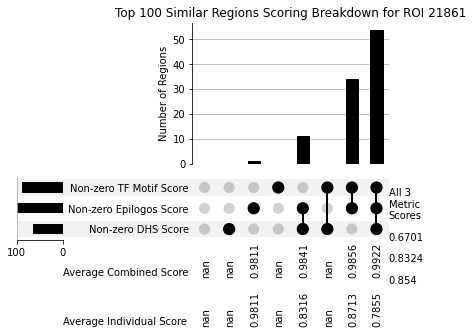

In [126]:
#top 100
mask_100_all3 = (DHS_arr[top_region_inds[1:]]!=0) & (TF_arr[top_region_inds[1:]]!=0) & (epilogos_arr[top_region_inds[1:]]!=0)
mask_100_dt = (DHS_arr[top_region_inds[1:]]!=0) & (TF_arr[top_region_inds[1:]]!=0) & (epilogos_arr[top_region_inds[1:]]==0)
mask_100_de = (DHS_arr[top_region_inds[1:]]!=0) & (TF_arr[top_region_inds[1:]]==0) & (epilogos_arr[top_region_inds[1:]]!=0)
mask_100_et = (DHS_arr[top_region_inds[1:]]==0) & (TF_arr[top_region_inds[1:]]!=0) & (epilogos_arr[top_region_inds[1:]]!=0)
mask_100_d = (DHS_arr[top_region_inds[1:]]!=0) & (TF_arr[top_region_inds[1:]]==0) & (epilogos_arr[top_region_inds[1:]]==0)
mask_100_t = (DHS_arr[top_region_inds[1:]]==0) & (TF_arr[top_region_inds[1:]]!=0) & (epilogos_arr[top_region_inds[1:]]==0)
mask_100_e = (DHS_arr[top_region_inds[1:]]==0) & (TF_arr[top_region_inds[1:]]==0) & (epilogos_arr[top_region_inds[1:]]!=0)
mask_100_none = (DHS_arr[top_region_inds[1:]]==0) & (TF_arr[top_region_inds[1:]]==0) & (epilogos_arr[top_region_inds[1:]]==0)

count_data = [len(DHS_arr[top_region_inds[1:]][mask_100_all3]), 
              len(DHS_arr[top_region_inds[1:]][mask_100_dt]), 
              len(DHS_arr[top_region_inds[1:]][mask_100_de]),
              len(DHS_arr[top_region_inds[1:]][mask_100_et]),
              len(DHS_arr[top_region_inds[1:]][mask_100_d]),
              len(DHS_arr[top_region_inds[1:]][mask_100_t]),
              len(DHS_arr[top_region_inds[1:]][mask_100_e]),
              len(DHS_arr[top_region_inds[1:]][mask_100_none])]

max_count_100 = np.max(count_data)

upset_data_top100 = upsetplot.from_memberships(
    [['Non-zero DHS Score', 'Non-zero TF Motif Score', 'Non-zero Epilogos Score'],
     ['Non-zero DHS Score', 'Non-zero TF Motif Score'],
     ['Non-zero DHS Score', 'Non-zero Epilogos Score'],
     ['Non-zero TF Motif Score', 'Non-zero Epilogos Score'],
     ['Non-zero DHS Score'],
     ['Non-zero TF Motif Score'],
     ['Non-zero Epilogos Score'],
     []
     ],
     data=count_data
)

comb_score_annot_100 = np.array([np.nan, 
                                 np.mean(score_arr[top_region_inds[1:]][mask_100_d]), 
                                 np.mean(score_arr[top_region_inds[1:]][mask_100_e]), 
                                 np.mean(score_arr[top_region_inds[1:]][mask_100_t]), 
                                 np.mean(score_arr[top_region_inds[1:]][mask_100_de]), 
                                 np.mean(score_arr[top_region_inds[1:]][mask_100_dt]),
                                 np.mean(score_arr[top_region_inds[1:]][mask_100_et]), 
                                 np.mean(score_arr[top_region_inds[1:]][mask_100_all3])])

individual_score_annot_100 = np.array([np.nan, 
                                       np.mean(DHS_arr[top_region_inds[1:]][mask_100_d]), 
                                       np.mean(epilogos_arr[top_region_inds[1:]][mask_100_e]),
                                       np.mean(TF_arr[top_region_inds[1:]][mask_100_t]), 
                                       np.mean([DHS_arr[top_region_inds[1:]][mask_100_de], 
                                                epilogos_arr[top_region_inds[1:]][mask_100_de]]), 
                                       np.mean([DHS_arr[top_region_inds[1:]][mask_100_dt], 
                                                TF_arr[top_region_inds[1:]][mask_100_dt]]), 
                                       np.mean([epilogos_arr[top_region_inds[1:]][mask_100_et], 
                                                TF_arr[top_region_inds[1:]][mask_100_et]]),
                                       np.mean([DHS_arr[top_region_inds[1:]][mask_100_all3], 
                                                epilogos_arr[top_region_inds[1:]][mask_100_all3], 
                                                TF_arr[top_region_inds[1:]][mask_100_all3]])])

all3_individual_scores_100 = np.array([np.mean(TF_arr[top_region_inds[1:]][mask_100_all3]), 
                                       np.mean(epilogos_arr[top_region_inds[1:]][mask_100_all3]), 
                                       np.mean(DHS_arr[top_region_inds[1:]][mask_100_all3])])

fig = plt.figure(figsize=(10,10))

upsetplot.plot(upset_data_top100, sort_categories_by=None)

plt.ylabel('Number of Regions')
title='Top 100 Similar Regions Scoring Breakdown for ROI %s' %(roi)
plt.title(title)


#annotate columns
comb_score_annot_100 = np.round(comb_score_annot_100, 4)
comb_y_pos=-45
for score, x_pos in zip(comb_score_annot_100, np.arange(-0.15, 7.85, 1)):
    plt.text(x_pos, comb_y_pos, score, rotation=90, weight='roman')
plt.text(-5.75, comb_y_pos, 'Average Combined Score', weight='roman')
    
indi_y_pos=-65
for score, x_pos in zip(np.round(individual_score_annot_100, 4), np.arange(-0.15, 7.85, 1)):
    plt.text(x_pos, indi_y_pos, score, rotation=90, weight='roman')
plt.text(-5.75, indi_y_pos, 'Average Individual Score', weight='roman')

adjustment = 0.065
for score, y_pos in zip(np.round(all3_individual_scores_100, 4), np.array([0.005, 0.035, 0.065])+adjustment):
    plt.text(0.54, y_pos, score, weight='roman', transform=fig.transFigure)

plt.text(0.54, 0.095 + adjustment, 'All 3\nMetric\nScores', weight='roman', transform=fig.transFigure)

    

print(title)
plt.show()

In [21]:
# fig = plt.figure(figsize=(10,10))

# upsetplot.plot(data, sort_categories_by=None)
# if log==True:
#     plt.yscale('log')

# plt.ylabel('Number of Regions')
# plt.title(title)

# for score, y_pos in zip(np.round(all3_individual_scores, 4), [0.12, 0.14, 0.16]):
#     plt.text(0.5, y_pos, score, weight='roman', transform=fig.transFigure)

# #annotate columns
# col_annot_data = np.round(col_annot_data, 4)

# for score, x_pos in zip(col_annot_data, np.arange(-0.15, 7.85, 1)):
#     plt.text(x_pos, comb_y_pos, score, rotation=90, weight='roman')

# plt.text(-5.75, comb_y_pos, 'Average Combined Score', weight='roman')
# print(title)
# plt.show()

ROI = 21861
#2 in ROIurl

DHS Cosine Similarity = 0.952
TF Cosine Similarity = 0.9025
Epilogos Cosine Similarity = 0.9904

1000th DHS Cosine Similarity for ROI = 0.7772
1000th TF Cosine Similarity for ROI = 0.8231
1000th Epilogos Cosine Similarity for ROI = 0.7487

DHS Scaled Score = 0.8774
TF Scaled Score = 0.8729
Epilogos Scaled Score = 0.9815

Total Score = 0.9997

Comparing OOE Values Between ROI (21861) and Rank 1 Similar Region (72689)


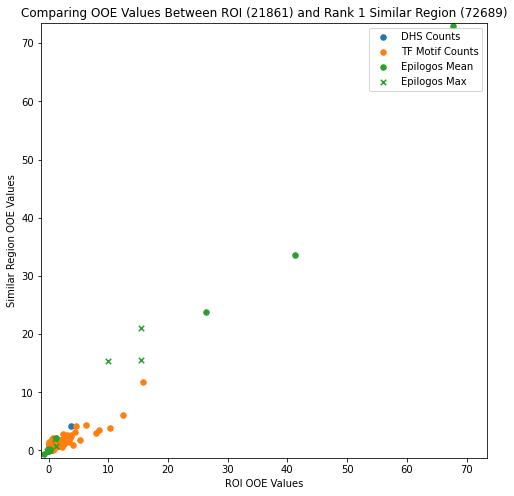

In [22]:
breakdown_score(1)

ROI = 21861
#100 in ROIurl

DHS Cosine Similarity = 0.5096
TF Cosine Similarity = 0.8661
Epilogos Cosine Similarity = 0.9273

1000th DHS Cosine Similarity for ROI = 0.7772
1000th TF Cosine Similarity for ROI = 0.8231
1000th Epilogos Cosine Similarity for ROI = 0.7487

DHS Scaled Score = 0.0
TF Scaled Score = 0.8254
Epilogos Scaled Score = 0.8601

Total Score = 0.9756

Comparing OOE Values Between ROI (21861) and Rank 99 Similar Region (64538)


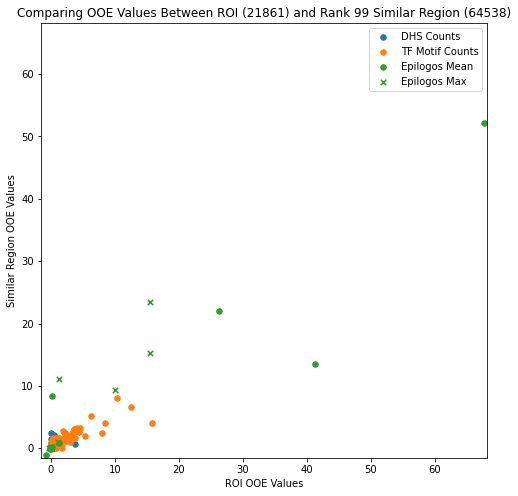

In [23]:
breakdown_score(99)

**OOE rank of each component across all regions**

In [24]:
rank_for_DHS_comps = rankdata(-DHS_ooe, method='average', axis=1)
rank_for_TF_comps = rankdata(-TF_ooe, method='average', axis=1)
rank_for_epilogos_mean_comps = rankdata(-epilogos_ooe[:, :18], method='average', axis=1)
rank_for_epilogos_max_comps = rankdata(-epilogos_ooe[:, 18:], method='average', axis=1)

Text(0.5, 1.0, 'TF Component Ranking Distribution\nAcross Regions (First 15 Components)')

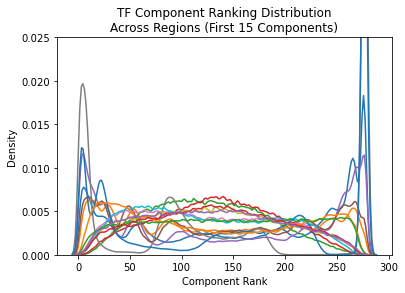

In [25]:
fig = plt.figure()
fig.patch.set_facecolor('white')
for i in range(len(rank_for_TF_comps[0, :15])):
    sns.kdeplot(rank_for_TF_comps[:, i], bw_adjust=0.2)
# plt.yscale('symlog')
plt.ylim([0, 0.025])
plt.xlabel('Component Rank')
plt.title('TF Component Ranking Distribution\nAcross Regions (First 15 Components)')

Text(0.5, 1.0, 'DHS Component Ranking Distribution Across Regions')

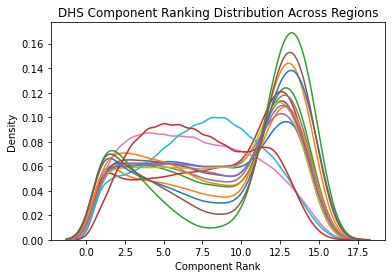

In [26]:
fig = plt.figure()
fig.patch.set_facecolor('white')
for i in range(len(rank_for_DHS_comps[0, :])):
    sns.kdeplot(rank_for_DHS_comps[:, i], bw_adjust=1.5)
plt.xlabel('Component Rank')
plt.title('DHS Component Ranking Distribution Across Regions')

Text(0.5, 1.0, 'Epilogos (Mean) Component Ranking Distribution Across Regions')

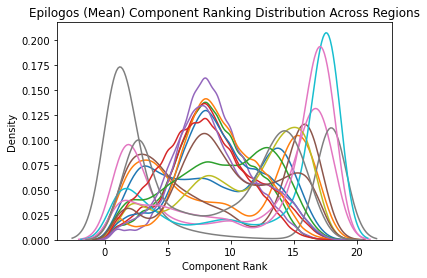

In [27]:
fig = plt.figure()
fig.patch.set_facecolor('white')
for i in range(len(rank_for_epilogos_mean_comps[0, :])):
    sns.kdeplot(rank_for_epilogos_mean_comps[:, i], bw_adjust=1.5)
plt.xlabel('Component Rank')
plt.title('Epilogos (Mean) Component Ranking Distribution Across Regions')

Text(0.5, 1.0, 'Epilogos (Max) Component Ranking Distribution Across Regions')

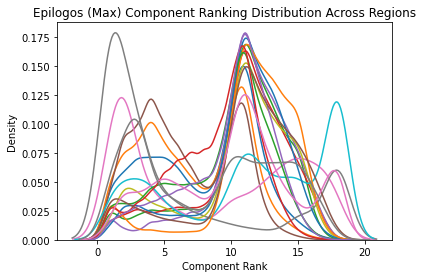

In [28]:
fig = plt.figure()
fig.patch.set_facecolor('white')
for i in range(len(rank_for_epilogos_max_comps[0, :])):
    sns.kdeplot(rank_for_epilogos_max_comps[:, i], bw_adjust=1.5)
plt.xlabel('Component Rank')
plt.title('Epilogos (Max) Component Ranking Distribution Across Regions')

**Generative Model for Epilogos Scores**

In [18]:
# epilogos_ooe_hdf5 = h5py.File('/home/ctrader/region_similarity/data/regions_25kb_CT20220623.epilogosoee.hdf5', 'r')
# epilogos_ooe_arr = epilogos_ooe_hdf5['ooe_arr'][:]
# epilogos_ooe_hdf5.close()

In [37]:
f = open('/home/ctrader/region_similarity/data/regions_25kb_CT20220623.epilogosmapped.bed', 'r')
epilogos_component_order = np.array(f.readline().strip().split('\t'))[3:]
f.close()

In [36]:
#load score data
epilogos_score_data = []
f = open('/home/ctrader/region_similarity/data/regions_25kb_CT20220623.epilogosmapped.bed', 'r')

next(f)
for line in f:
    epilogos_score_data.append(re.split('\t|\|', line.strip()))
f.close()
epilogos_score_data = np.array(epilogos_score_data)

epilogos_score_data_mean_vals = epilogos_score_data[:, 3::2].astype(float)
epilogos_score_data_max_vals = epilogos_score_data[:, 4::2].astype(float)

In [38]:
top_epilogos_max_comp = np.argmax(epilogos_score_data_max_vals, axis=1)
top_epilogos_mean_comp = np.argmax(epilogos_score_data_mean_vals, axis=1)

In [40]:
epilogos_component_order
epilogos_mapped_color_order = np.array(['#ffc34d', '#ffc34d', '#bdb76b', '#c2e105', '#c2e105', '#ffff00', '#8a91d0', 
                                        '#ffffff', '#808080', '#c0c0c0', '#ff0000', '#cd5c5c', '#ff4500', '#ff4500', 
                                        '#ff4500', '#008000', '#006400', '#66cdaa'])


Top Epilogos Factor for Each 25kb Region


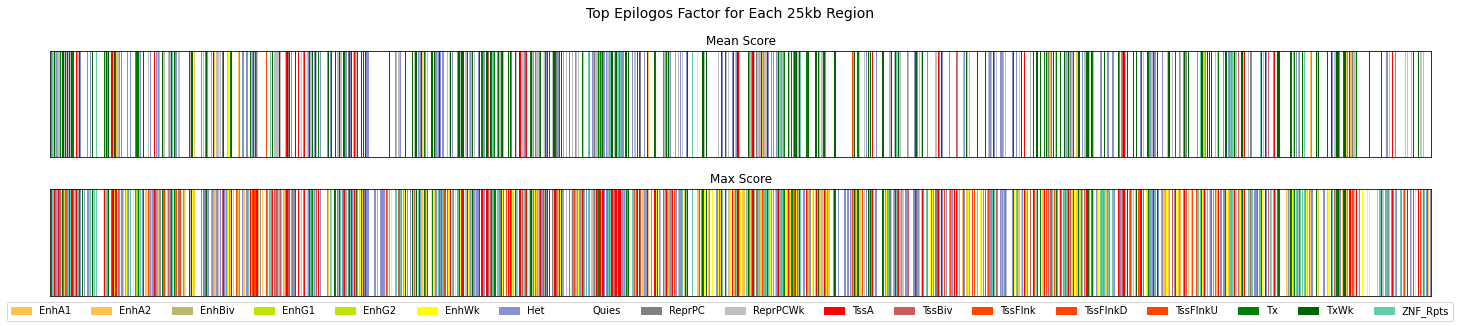

In [41]:
fig, axes = plt.subplots(nrows=2, figsize=(20,4))
fig.patch.set_facecolor('white')
fig.tight_layout()

axes[0].bar(np.arange(len(top_epilogos_mean_comp)), 1, color=epilogos_mapped_color_order[top_epilogos_mean_comp], width=1)
axes[1].bar(np.arange(len(top_epilogos_max_comp)), 1, color=epilogos_mapped_color_order[top_epilogos_max_comp], width=1)

axes[0].set_xlim([0, len(top_epilogos_mean_comp)])
axes[0].set_ylim([0, 1])
axes[1].set_xlim([0, len(top_epilogos_max_comp)])
axes[1].set_ylim([0, 1])

axes[0].set_xticks([])
axes[0].set_yticks([])
axes[1].set_xticks([])
axes[1].set_yticks([])

axes[0].set_title('Mean Score')
axes[1].set_title('Max Score')

handles = []
for c, f in zip(epilogos_mapped_color_order, epilogos_component_order):
    handles.append(mpatches.Patch(color=c, label=f))

fig.legend(handles=handles, loc='lower center', ncol=18)

title = 'Top Epilogos Factor for Each 25kb Region'
fig.suptitle(title, y=1.1, fontsize=14)
print(title)

In [42]:
#counting intersection of epilogos max and mean factors
top_epilogos_comp_max_mean_counts = np.zeros((18, 18), dtype=int)
for i, j in zip(top_epilogos_mean_comp, top_epilogos_max_comp):
    top_epilogos_comp_max_mean_counts[i, j] += 1

Text(0.5, 1.0, 'Chromatin State Top Factors for All Regions')

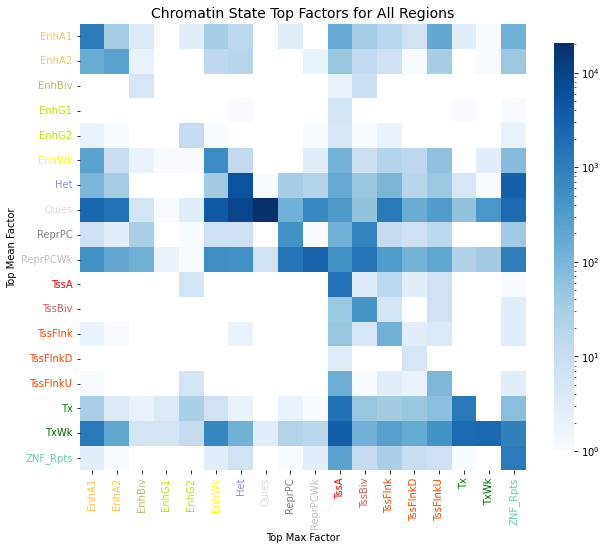

In [65]:
fig, axes = plt.subplots(figsize=(10,10))
fig.patch.set_facecolor('white')

sns.heatmap(top_epilogos_comp_max_mean_counts, cmap='Blues', square=True, norm=LogNorm(), cbar_kws={"shrink": .75})

axes.set_xticklabels(epilogos_component_order, rotation=90)
axes.set_yticklabels(epilogos_component_order, rotation=0)

colors_for_heatmap = epilogos_mapped_color_order
colors_for_heatmap[7]='#dbdbdb'
for (color, xlabel, ylabel) in zip(epilogos_mapped_color_order, axes.xaxis.get_ticklabels(), axes.yaxis.get_ticklabels()):
    xlabel.set_color(color)
    ylabel.set_color(color)

title='Chromatin State Top Factors for All Regions'

plt.ylabel('Top Mean Factor')
plt.xlabel('Top Max Factor')
plt.title(title, fontsize=14)

In [34]:
# up = np.arange(0, top_max_factor_val, top_max_factor_val/(25000/200/2))
# down = np.arange(top_max_factor_val, 0, -top_max_factor_val/(25000/200/2))[:-1]
# max_path = np.append(up, down)
# max_path

# fig = plt.figure(figsize=(10,6))
# fig.patch.set_facecolor('white')

# top_mean_factor = np.argmax(epilogos_score_data_mean_vals[roi])
# noise = [0]
# for i in range(1, int(25000/200)):
#     noise.append(noise[i-1]+random.gauss(0, 0.1))
# noise = np.array(noise)
# mean_cartoon = np.array([epilogos_score_data_mean_vals[roi, top_mean_factor]]*int(25000/200)) + noise

# top_max_factor = np.argmax(epilogos_score_data_max_vals[roi])
# top_max_factor_val = epilogos_score_data_max_vals[roi, top_max_factor]

# up = np.arange(0, top_max_factor_val, top_max_factor_val/(25000/200/2))
# down = np.arange(top_max_factor_val, 0, -top_max_factor_val/(25000/200/2))[:-1]


# max_cartoon = np.append(up, down)

# plt.fill_between(np.arange(0, 25000, 200), mean_cartoon, color=epilogos_mapped_color_order[top_mean_factor])
# plt.fill_between(np.arange(0, 25000, 200), max_cartoon, color=epilogos_mapped_color_order[top_max_factor])

Text(0.51, 0.98, 'Summerized Chromatin State Pattern for ROI 21861')

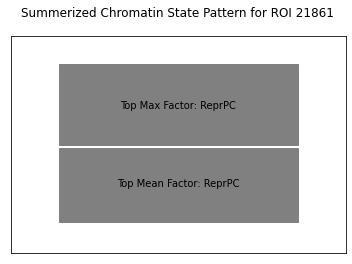

In [78]:
fig, axes = plt.subplots(figsize=(6,4))
fig.patch.set_facecolor('white')

top_mean_factor = np.argmax(epilogos_score_data_mean_vals[roi])
top_max_factor = np.argmax(epilogos_score_data_max_vals[roi])


mean_patch = mpatches.Rectangle((0, 0), 1, 0.48, angle=0.0, color=epilogos_mapped_color_order[top_mean_factor])
axes.add_patch(mean_patch)
axes.text(0.5, 0.25, 'Top Mean Factor: %s' %(epilogos_component_order[top_mean_factor]), ha='center', va='center')

max_patch = mpatches.Rectangle((0, 0.5), 1, 0.52, angle=0.0, color=epilogos_mapped_color_order[top_max_factor])
axes.add_patch(max_patch)
axes.text(0.5, 0.75, 'Top Max Factor: %s' %(epilogos_component_order[top_max_factor]), ha='center', va='center')

axes.set_xlim([-0.2, 1.2])
axes.set_ylim([-0.2, 1.2])

axes.set_xticks([])
axes.set_yticks([])

fig.suptitle('Summerized Chromatin State Pattern for ROI %s' %(roi), x=0.51)

**Finding Most Interesting Region**

In [13]:
# epilogos_scaled_vals_full
# epilogos_similar_regions_full
# TF_scaled_vals_full
# TF_similar_regions_full
# DHS_scaled_vals_full
# DHS_similar_regions_full

In [433]:
regions_scores = []
DHS_individual_scores = []
TF_individual_scores = []
epilogos_individual_scores = []
for i in range(len(DHS_similar_regions_full)):
    DHS_arr_i = np.zeros(len(DHS_similar_regions_full))
    TF_arr_i = np.zeros(len(TF_similar_regions_full))
    epilogos_arr_i = np.zeros(len(epilogos_similar_regions_full))

    DHS_arr_i[DHS_similar_regions_full[i]] = DHS_scaled_vals_full[i]
    TF_arr_i[TF_similar_regions_full[i]] = TF_scaled_vals_full[i]
    epilogos_arr_i[epilogos_similar_regions_full[i]] = epilogos_scaled_vals_full[i]
    
    score_arr_i = 1 - ((1 - epilogos_arr_i) * (1 - DHS_arr_i) * (1 - TF_arr_i))
    top_100_inds = np.argsort(-score_arr_i)[:100]
    
    regions_scores.append(score_arr_i[top_100_inds])
    DHS_individual_scores.append(DHS_arr_i[top_100_inds])
    TF_individual_scores.append(TF_arr_i[top_100_inds])
    epilogos_individual_scores.append(epilogos_arr_i[top_100_inds])
    
regions_scores = np.array(regions_scores)
DHS_individual_scores = np.array(DHS_individual_scores)
TF_individual_scores = np.array(TF_individual_scores)
epilogos_individual_scores = np.array(epilogos_individual_scores)

In [434]:
average_of_scores = np.mean([np.mean(DHS_individual_scores, axis=1), 
                             np.mean(TF_individual_scores, axis=1), 
                             np.mean(epilogos_individual_scores, axis=1),
                             np.mean(regions_scores, axis=1)], 
                            axis=0)

In [435]:
np.argsort(-average_of_scores)[20000]

67717